# Production and Growth of Overexpression Strains

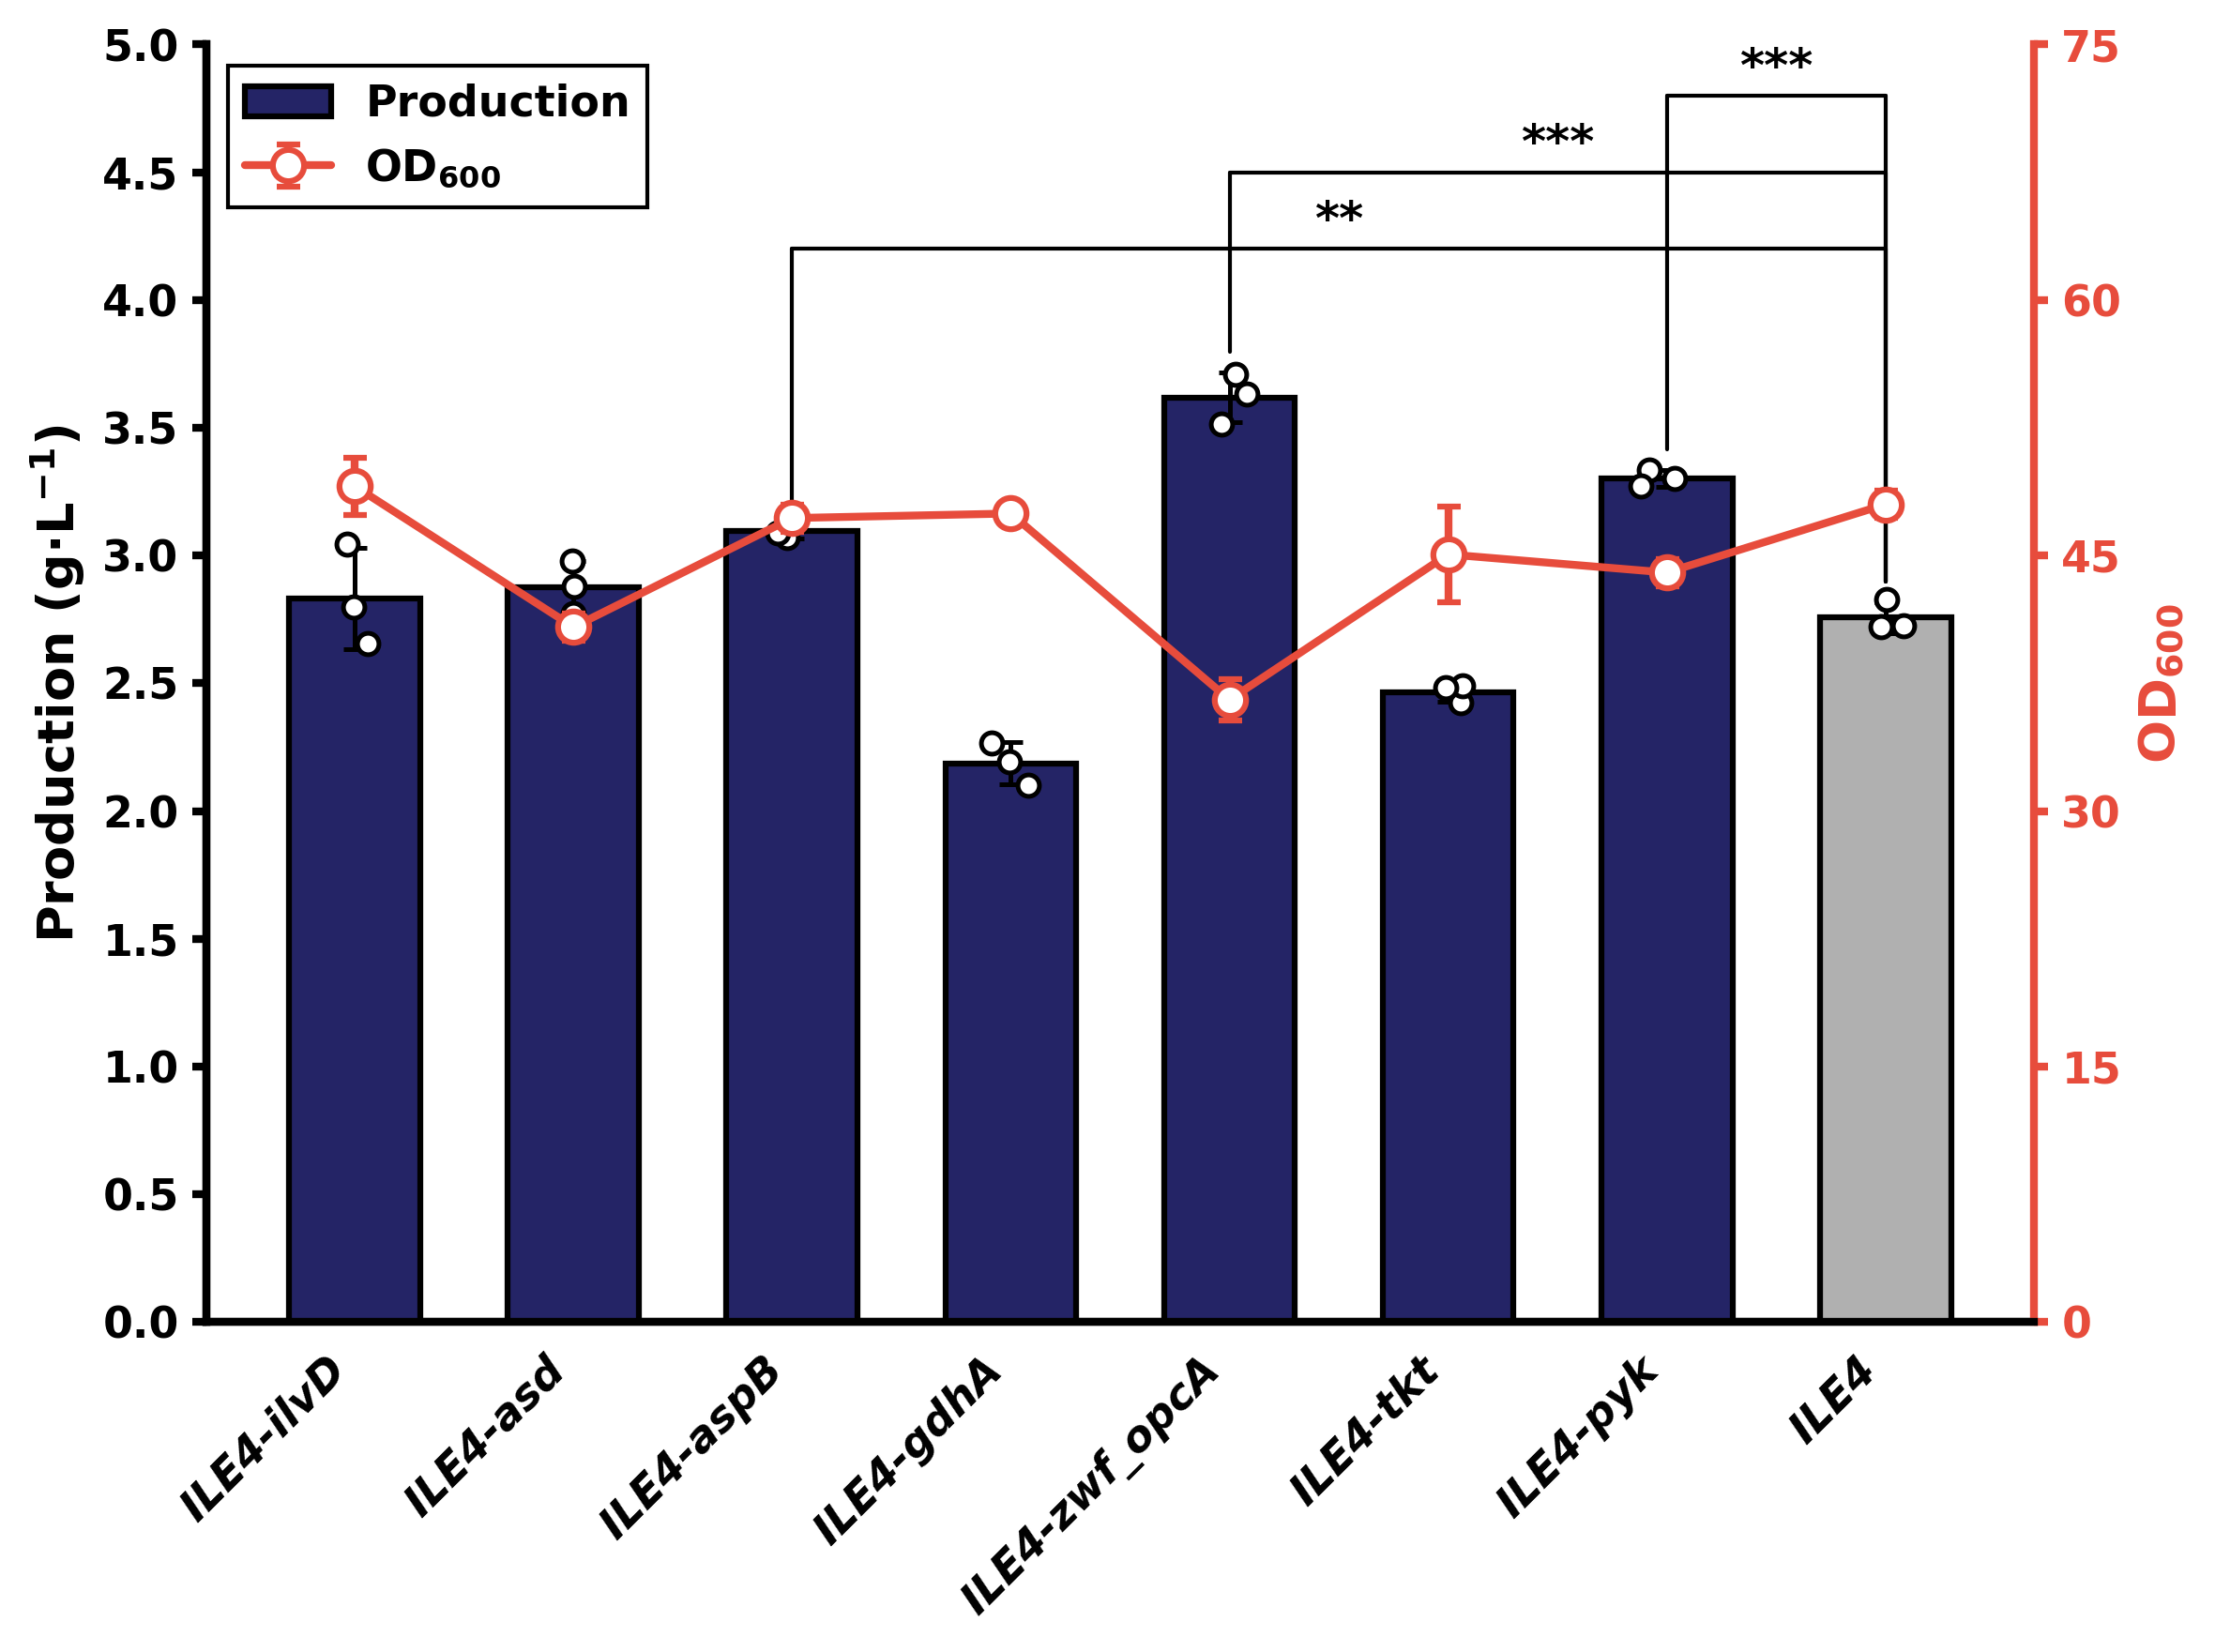


统计结果 (与ILE4比较)
对照组 (ILE4) 产量: 2.758 g/L
Strain       Production (g/L)     OD600           Sig    P-value    变化      
------------------------------------------------------------
ILE4-ilvD    2.833 ± 0.198        49.1 ± 1.7      ns     0.5651     ↑ +2.7% 
ILE4-asd     2.877 ± 0.102        40.8 ± 0.8      ns     0.1585     ↑ +4.3% 
ILE4-aspB    3.097 ± 0.032        47.2 ± 0.8      **     0.0010     ↑ +12.3%
ILE4-gdhA    2.187 ± 0.083        47.5 ± 0.5      ***    0.0007     ↓ -20.7%
ILE4-zwf_opcA 3.619 ± 0.097        36.5 ± 1.2      ***    0.0002     ↑ +31.2%
ILE4-tkt     2.465 ± 0.037        45.1 ± 2.8      **     0.0020     ↓ -10.6%
ILE4-pyk     3.302 ± 0.032        44.0 ± 0.8      ***    0.0002     ↑ +19.7%
ILE4         2.758 ± 0.061        48.0 ± 0.8      -      -          -       
产量提高且显著的菌株数量: 3
产量提高且显著的菌株: ILE4-aspB, ILE4-zwf_opcA, ILE4-pyk


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

std_conc = np.array([1, 2.5, 5, 7.5, 10])
std_area = np.array([4102.884, 9896.064, 19627.373, 29058.028, 35211.635])
slope, intercept, _, _, _ = stats.linregress(std_area, std_conc)

def area_to_conc(area):
    return slope * area + intercept

raw_data = {

    'ILE4-ilvD':     ([47.2, 49.6, 50.4], [11049.603, 10541.312, 11930.252]),
    'ILE4-asd':      ([40,   40.8, 41.6], [10960.954, 11341.242, 11686.527]),
    'ILE4-aspB':     ([47.2, 46.4, 48],   [12011.333, 12232.61,  12088.114]),
    'ILE4-gdhA':     ([47.2, 47.2, 48],   [8576.132,  9165.155,  8899.337]),
    'ILE4-zwf_opcA': ([36.8, 35.2, 37.6], [14018.228, 13597.353, 14279.286]),
    'ILE4-tkt':      ([48,   44.8, 42.4], [9715.859,  9955.499,  9929.419]),
    'ILE4-pyk':      ([44,   44.8, 43.2], [12838.605, 12955.947, 12728.481]),
    'ILE4':  ([47.2, 48.8, 48],   [10783.173, 10784.636, 11156.228]),
}

strains = []
od_data = {}
prod_data = {}

for strain, (od_list, area_list) in raw_data.items():
    strains.append(strain)
    od_data[strain] = od_list
    prod_data[strain] = [area_to_conc(a) for a in area_list]

prod_means = [np.mean(prod_data[s]) for s in strains]
prod_stds = [np.std(prod_data[s], ddof=1) for s in strains]
od_means = [np.mean(od_data[s]) for s in strains]
od_stds = [np.std(od_data[s], ddof=1) for s in strains]

def calc_significance(group1, group2):
    _, p = stats.ttest_ind(group1, group2)
    if p < 0.001: return '***', p
    elif p < 0.01: return '**', p
    elif p < 0.05: return '*', p
    return 'ns', p

control_idx = strains.index('ILE4')
control_mean = prod_means[control_idx]

significance = {}
for strain in strains:
    if strain != 'ILE4':
        sig, p = calc_significance(prod_data[strain], prod_data['ILE4'])
        significance[strain] = (sig, p)

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'font.weight': 'bold',
    'axes.linewidth': 2,
    'axes.labelweight': 'bold',
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'figure.dpi': 300
})

fig, ax = plt.subplots(figsize=(8, 6))

fig.patch.set_facecolor('white')
ax.set_facecolor('white')
ax.grid(False)

x = np.arange(len(strains))
width = 0.6

bar_color = '#242466'
control_color = '#B0B0B0'
od_color = '#E74C3C'

colors = [control_color if s == 'ILE4' else bar_color for s in strains]

ax.bar(x, prod_means, width,
              yerr=prod_stds,
              color=colors,
              edgecolor='black',
              linewidth=1.5,
              capsize=3,
              error_kw={'linewidth': 1.2, 'capthick': 1.2, 'color': 'black'},
              label='Production',
              zorder=3)

for i, strain in enumerate(strains):
    y_points = prod_data[strain]
    x_points = np.random.normal(i, 0.05, len(y_points))
    ax.scatter(x_points, y_points, facecolor='white', edgecolor='black',
               s=30, zorder=5, linewidth=1.2)

ax.set_ylabel('Production (g·L$^{-1}$)', fontsize=13, fontweight='bold', color='black')
ax.set_ylim(0, 5.0)
ax.set_yticks(np.arange(0, 5.5, 0.5))
ax.tick_params(axis='y', colors='black', labelcolor='black')

ax2 = ax.twinx()
ax2.set_facecolor('none')
ax2.grid(False)
ax2.errorbar(x, od_means, yerr=od_stds,
                    color=od_color,
                    marker='o',
                    markersize=8,
                    markerfacecolor='white',
                    markeredgecolor=od_color,
                    markeredgewidth=1.5,
                    linewidth=2,
                    capsize=3,
                    capthick=1.2,
                    label='OD$_{600}$',
                    zorder=10)

ax2.set_ylabel('OD$_{600}$', fontsize=13, fontweight='bold', color=od_color)
ax2.set_ylim(0, 75)
ax2.set_yticks(np.arange(0, 80, 15))
ax2.spines['right'].set_color(od_color)

ax.set_xticks(x)
ax.set_xticklabels(strains, fontsize=11, style='italic', fontweight='bold', rotation=45, ha='right', color='black')
ax.tick_params(axis='x', width=2, labelsize=11, colors='black', labelcolor='black')
ax.tick_params(axis='y', width=2, labelsize=11, colors='black', labelcolor='black')
ax2.tick_params(axis='y', width=2, labelsize=11, labelcolor=od_color, colors=od_color)

significant_improved = []
for i, strain in enumerate(strains):
    if strain != 'ILE4':
        sig, p = significance[strain]

        if sig != 'ns' and prod_means[i] > control_mean:
            significant_improved.append((i, strain, sig))

y_base = 4.2
y_step = 0.30

for rank, (idx, strain, sig) in enumerate(significant_improved):
    y_line = y_base + rank * y_step

    left = min(idx, control_idx)
    right = max(idx, control_idx)

    bar_top_left = prod_means[left] + prod_stds[left] + 0.08
    bar_top_right = prod_means[right] + prod_stds[right] + 0.08

    ax.plot([left, left], [bar_top_left, y_line], 'k-', linewidth=1)
    ax.plot([left, right], [y_line, y_line], 'k-', linewidth=1)
    ax.plot([right, right], [y_line, bar_top_right], 'k-', linewidth=1)

    ax.text((left + right) / 2, y_line + 0.02, sig,
            ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_linewidth(2)
ax.spines['bottom'].set_color('black')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_linewidth(2)
ax2.spines['right'].set_color(od_color)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
legend = ax.legend(h1 + h2, l1 + l2, loc='upper left', frameon=True,
                   edgecolor='black', fancybox=False, fontsize=11,
                   framealpha=1, facecolor='white')
legend.get_frame().set_linewidth(1)

plt.tight_layout()
plt.savefig('strain_production_od_OE.png', dpi=600, bbox_inches='tight', facecolor='white')
plt.show()

print("\n" + "="*60)
print("统计结果 (与ILE4比较)")
print("="*60)
print(f"对照组 (ILE4) 产量: {control_mean:.3f} g/L")
print("="*60)
print(f"{'Strain':<12} {'Production (g/L)':<20} {'OD600':<15} {'Sig':<6} {'P-value':<10} {'变化':<8}")
print("-"*60)
for i, strain in enumerate(strains):
    prod_str = f"{prod_means[i]:.3f} ± {prod_stds[i]:.3f}"
    od_str = f"{od_means[i]:.1f} ± {od_stds[i]:.1f}"
    sig, p = significance.get(strain, ('-', 0))
    p_str = f"{p:.4f}" if strain in significance else "-"

    if strain != 'ILE4':
        change = "↑" if prod_means[i] > control_mean else "↓"
        change_pct = f"{((prod_means[i] - control_mean) / control_mean * 100):+.1f}%"
        change_str = f"{change} {change_pct}"
    else:
        change_str = "-"

    print(f"{strain:<12} {prod_str:<20} {od_str:<15} {sig:<6} {p_str:<10} {change_str:<8}")
print("="*60)
print(f"产量提高且显著的菌株数量: {len(significant_improved)}")
if significant_improved:
    print(f"产量提高且显著的菌株: {', '.join([s[1] for s in significant_improved])}")
else:
    print("无产量提高且显著的菌株")


# Production and Growth of Knockdown Strains

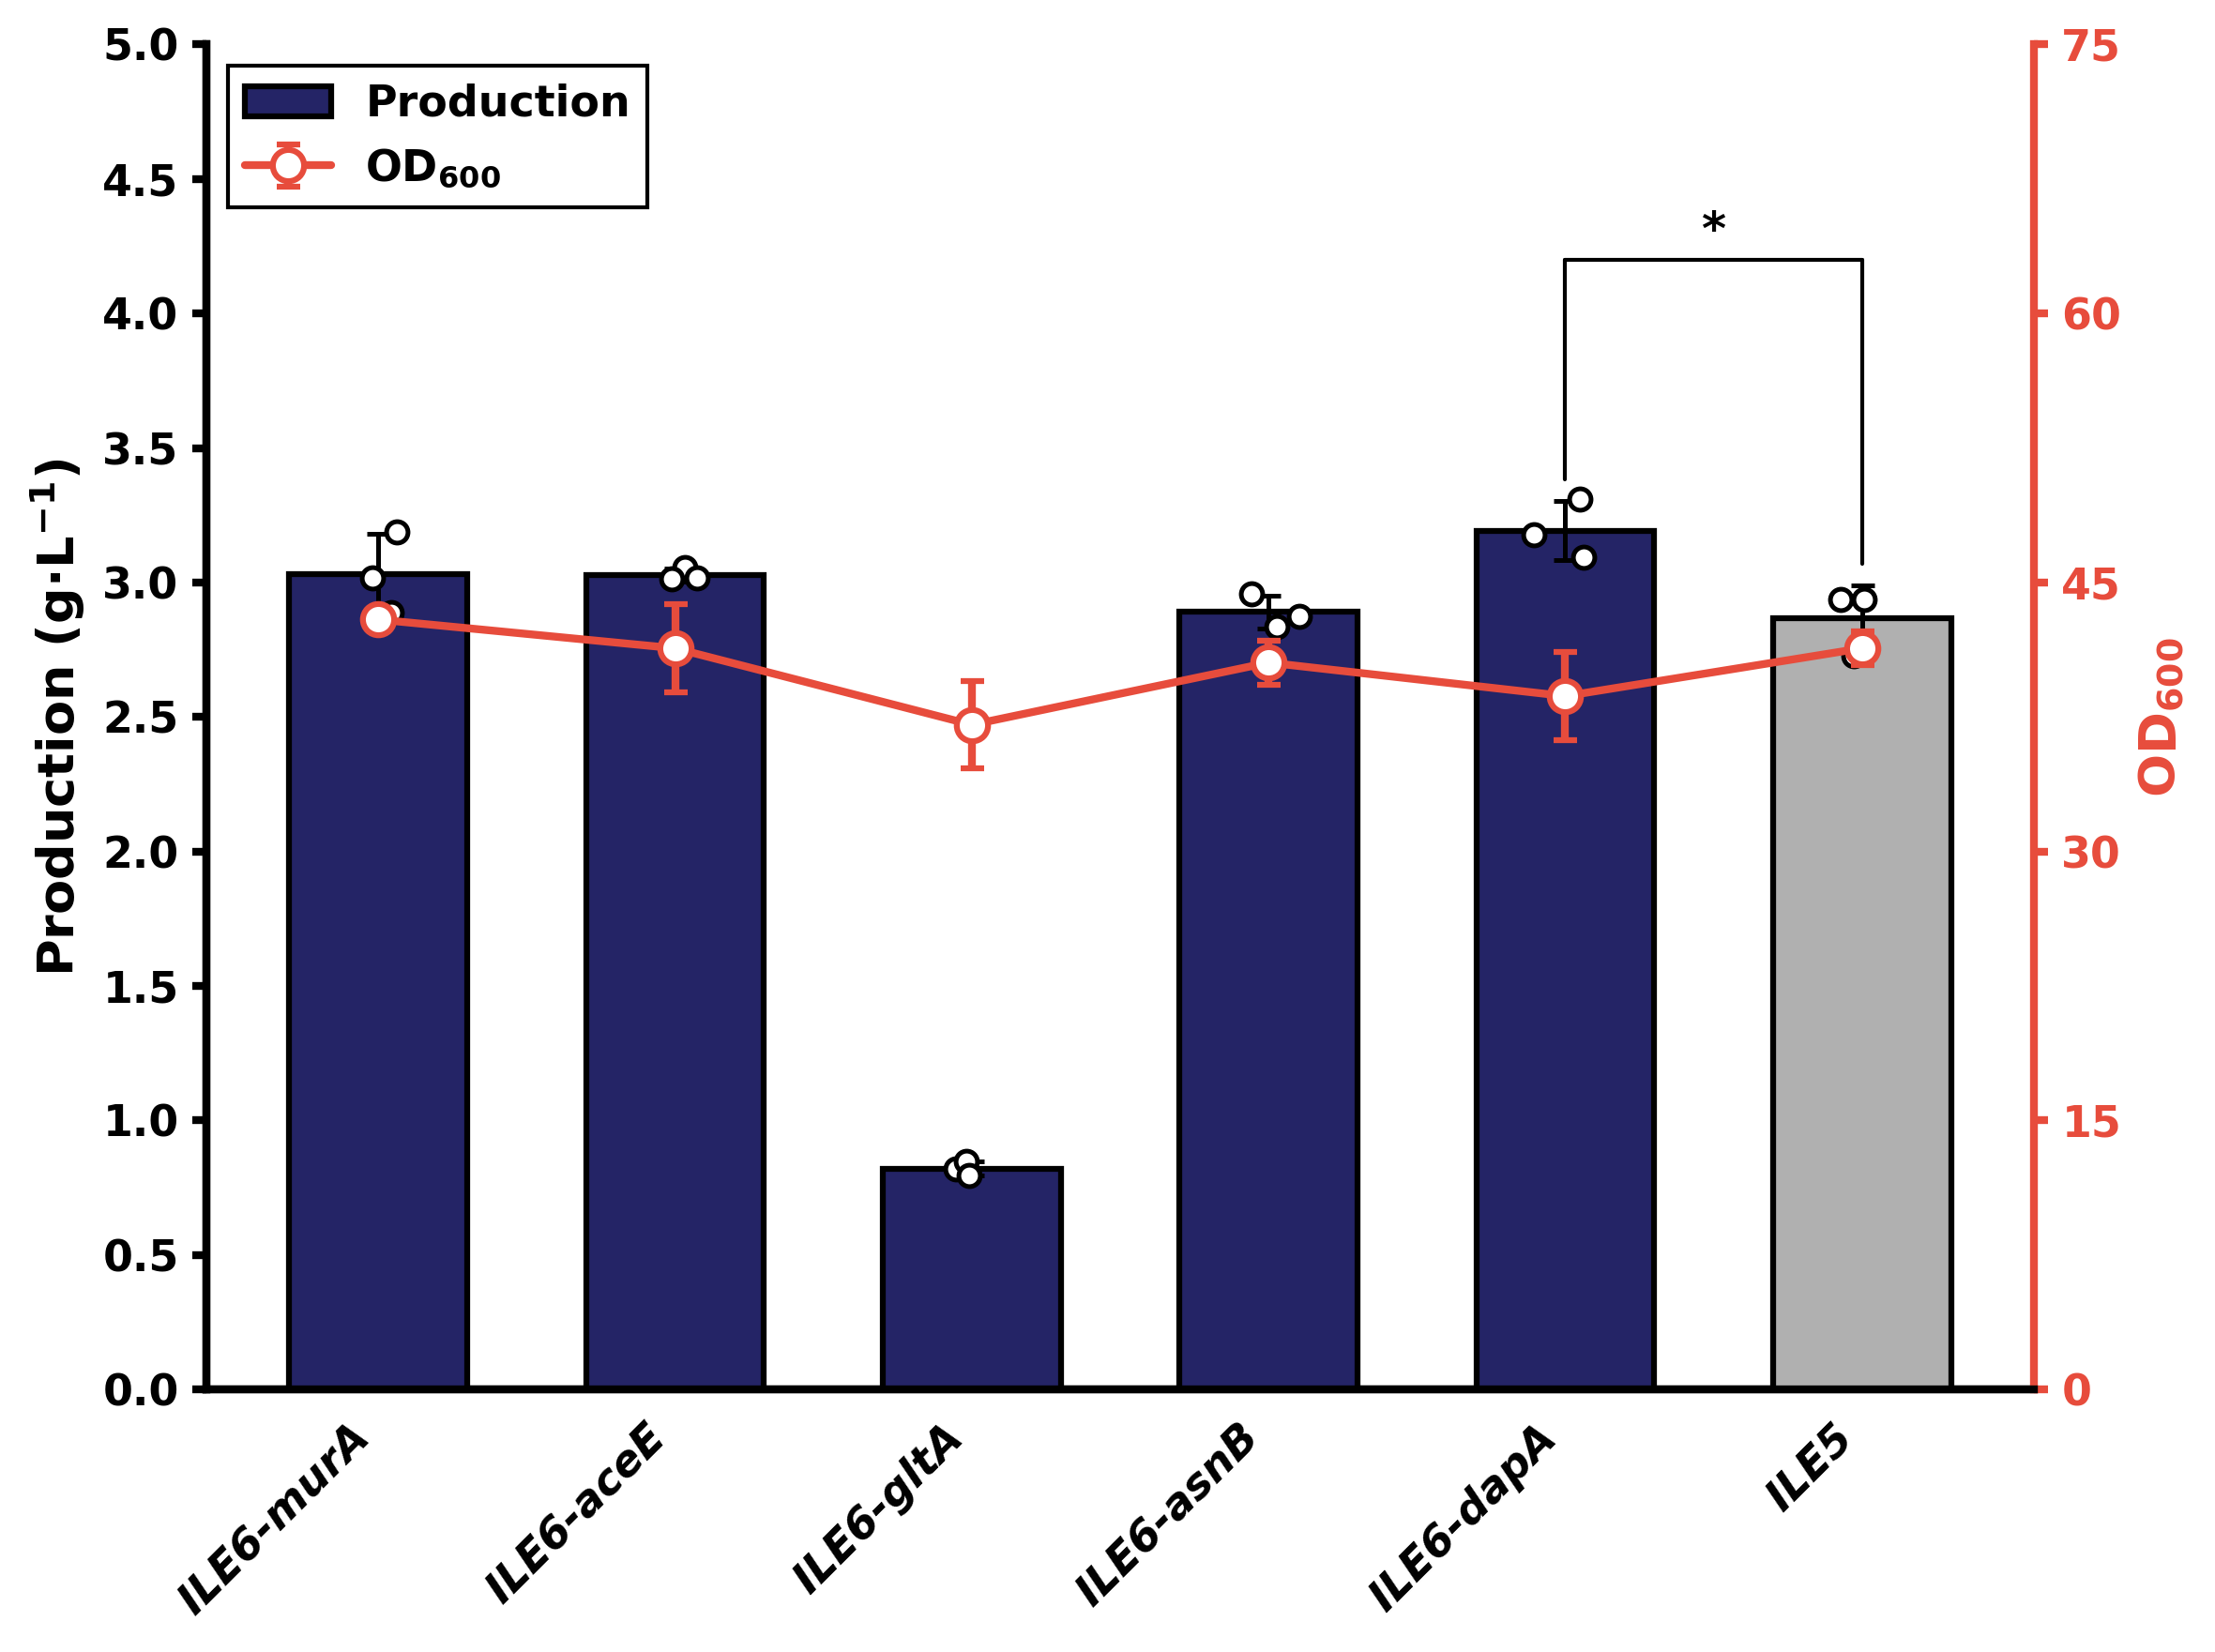


统计结果 (与ILE5比较)
对照组 (ILE5) 产量: 2.868 g/L
Strain       Production (g/L)     OD600           Sig    P-value    变化      
------------------------------------------------------------
ILE6-murA    3.031 ± 0.150        42.9 ± 0.5      ns     0.2156     ↑ +5.7% 
ILE6-aceE    3.028 ± 0.024        41.3 ± 2.4      ns     0.0871     ↑ +5.6% 
ILE6-gltA    0.821 ± 0.026        37.1 ± 2.4      ***    0.0000     ↓ -71.4%
ILE6-asnB    2.890 ± 0.061        40.5 ± 1.2      ns     0.7888     ↑ +0.8% 
ILE6-dapA    3.193 ± 0.110        38.7 ± 2.4      *      0.0261     ↑ +11.4%
ILE5         2.868 ± 0.121        41.3 ± 0.9      -      -          -       
产量提高且显著的菌株数量: 1
产量提高且显著的菌株: ILE6-dapA


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

std_conc = np.array([1, 2.5, 5, 7.5, 10])
std_area = np.array([4102.884, 9896.064, 19627.373, 29058.028, 35211.635])
slope, intercept, _, _, _ = stats.linregress(std_area, std_conc)

def area_to_conc(area):
    return slope * area + intercept

raw_data = {

    'ILE6-murA':     ([42.4,43.2,43.2], [12433, 11368, 11834]),
    'ILE6-aceE':      ([39.2,40.8,44], [11966, 11815, 11822]),
    'ILE6-gltA':     ([34.4,37.6,39.2],   [4021,4126,3939]),
    'ILE6-asnB':      ([39.2,40.8,41.6], [11614,11189,11326]),
    'ILE6-dapA':     ([36,39.2,40.8],   [12095,12868,12395]),
    'ILE5':     ([40.8,40.8,42.4], [11542,11548,10800]),
}

strains = []
od_data = {}
prod_data = {}

for strain, (od_list, area_list) in raw_data.items():
    strains.append(strain)
    od_data[strain] = od_list
    prod_data[strain] = [area_to_conc(a) for a in area_list]

prod_means = [np.mean(prod_data[s]) for s in strains]
prod_stds = [np.std(prod_data[s], ddof=1) for s in strains]
od_means = [np.mean(od_data[s]) for s in strains]
od_stds = [np.std(od_data[s], ddof=1) for s in strains]

def calc_significance(group1, group2):
    _, p = stats.ttest_ind(group1, group2)
    if p < 0.001: return '***', p
    elif p < 0.01: return '**', p
    elif p < 0.05: return '*', p
    return 'ns', p

control_idx = strains.index('ILE5')
control_mean = prod_means[control_idx]

significance = {}
for strain in strains:
    if strain != 'ILE5':
        sig, p = calc_significance(prod_data[strain], prod_data['ILE5'])
        significance[strain] = (sig, p)

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'font.weight': 'bold',
    'axes.linewidth': 2,
    'axes.labelweight': 'bold',
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'figure.dpi': 300
})

fig, ax = plt.subplots(figsize=(8, 6))

fig.patch.set_facecolor('white')
ax.set_facecolor('white')
ax.grid(False)

x = np.arange(len(strains))
width = 0.6

bar_color = '#242466'
control_color = '#B0B0B0'
od_color = '#E74C3C'

colors = [control_color if s == 'ILE5' else bar_color for s in strains]

ax.bar(x, prod_means, width,
              yerr=prod_stds,
              color=colors,
              edgecolor='black',
              linewidth=1.5,
              capsize=3,
              error_kw={'linewidth': 1.2, 'capthick': 1.2, 'color': 'black'},
              label='Production',
              zorder=3)

for i, strain in enumerate(strains):
    y_points = prod_data[strain]
    x_points = np.random.normal(i, 0.05, len(y_points))
    ax.scatter(x_points, y_points, facecolor='white', edgecolor='black',
               s=30, zorder=5, linewidth=1.2)

ax.set_ylabel('Production (g·L$^{-1}$)', fontsize=13, fontweight='bold', color='black')
ax.set_ylim(0, 5.0)
ax.set_yticks(np.arange(0, 5.5, 0.5))
ax.tick_params(axis='y', colors='black', labelcolor='black')

ax2 = ax.twinx()
ax2.set_facecolor('none')
ax2.grid(False)
ax2.errorbar(x, od_means, yerr=od_stds,
                    color=od_color,
                    marker='o',
                    markersize=8,
                    markerfacecolor='white',
                    markeredgecolor=od_color,
                    markeredgewidth=1.5,
                    linewidth=2,
                    capsize=3,
                    capthick=1.2,
                    label='OD$_{600}$',
                    zorder=10)

ax2.set_ylabel('OD$_{600}$', fontsize=13, fontweight='bold', color=od_color)
ax2.set_ylim(0, 75)
ax2.set_yticks(np.arange(0, 80, 15))
ax2.spines['right'].set_color(od_color)

ax.set_xticks(x)
ax.set_xticklabels(strains, fontsize=11, style='italic', fontweight='bold', rotation=45, ha='right', color='black')
ax.tick_params(axis='x', width=2, labelsize=11, colors='black', labelcolor='black')
ax.tick_params(axis='y', width=2, labelsize=11, colors='black', labelcolor='black')
ax2.tick_params(axis='y', width=2, labelsize=11, labelcolor=od_color, colors=od_color)

significant_improved = []
for i, strain in enumerate(strains):
    if strain != 'ILE5':
        sig, p = significance[strain]

        if sig != 'ns' and prod_means[i] > control_mean:
            significant_improved.append((i, strain, sig))

y_base = 4.2
y_step = 0.30

for rank, (idx, strain, sig) in enumerate(significant_improved):
    y_line = y_base + rank * y_step

    left = min(idx, control_idx)
    right = max(idx, control_idx)

    bar_top_left = prod_means[left] + prod_stds[left] + 0.08
    bar_top_right = prod_means[right] + prod_stds[right] + 0.08

    ax.plot([left, left], [bar_top_left, y_line], 'k-', linewidth=1)
    ax.plot([left, right], [y_line, y_line], 'k-', linewidth=1)
    ax.plot([right, right], [y_line, bar_top_right], 'k-', linewidth=1)

    ax.text((left + right) / 2, y_line + 0.02, sig,
            ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_linewidth(2)
ax.spines['bottom'].set_color('black')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_linewidth(2)
ax2.spines['right'].set_color(od_color)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
legend = ax.legend(h1 + h2, l1 + l2, loc='upper left', frameon=True,
                   edgecolor='black', fancybox=False, fontsize=11,
                   framealpha=1, facecolor='white')
legend.get_frame().set_linewidth(1)

plt.tight_layout()
plt.savefig('strain_production_od_KD.png', dpi=600, bbox_inches='tight', facecolor='white')
plt.show()

print("\n" + "="*60)
print("统计结果 (与ILE5比较)")
print("="*60)
print(f"对照组 (ILE5) 产量: {control_mean:.3f} g/L")
print("="*60)
print(f"{'Strain':<12} {'Production (g/L)':<20} {'OD600':<15} {'Sig':<6} {'P-value':<10} {'变化':<8}")
print("-"*60)
for i, strain in enumerate(strains):
    prod_str = f"{prod_means[i]:.3f} ± {prod_stds[i]:.3f}"
    od_str = f"{od_means[i]:.1f} ± {od_stds[i]:.1f}"
    sig, p = significance.get(strain, ('-', 0))
    p_str = f"{p:.4f}" if strain in significance else "-"

    if strain != 'ILE5':
        change = "↑" if prod_means[i] > control_mean else "↓"
        change_pct = f"{((prod_means[i] - control_mean) / control_mean * 100):+.1f}%"
        change_str = f"{change} {change_pct}"
    else:
        change_str = "-"

    print(f"{strain:<12} {prod_str:<20} {od_str:<15} {sig:<6} {p_str:<10} {change_str:<8}")
print("="*60)
print(f"产量提高且显著的菌株数量: {len(significant_improved)}")
if significant_improved:
    print(f"产量提高且显著的菌株: {', '.join([s[1] for s in significant_improved])}")
else:
    print("无产量提高且显著的菌株")


# Agreement Between Experimental and Simulated Values

In [3]:
import numpy as np


reaction_data=[
("glc_upt/pts",1.7814,1.7814),("pgi",0.8224,1.4642),("pfk",1.3313,1.4671),("fda",1.3313,1.4671),("tpi",1.3313,1.44),
("gapA",2.8914,2.8952),("eno",2.6708,2.7336),("pdh",1.7789,1.632),("gltA",1.3317,1.1657),("acn",1.3317,1.1657),
("icd",1.3317,1.1657),("odh",0.5734+0.5734,0.9446),("sdh",0.5734+0.5734,0.9439),("fumC",0.5734+0.5734,0.5524),("zwf",0.9287,0.3043),
("gnd",0.9287,0.3043),("rpe",0.5194,0.0188),("rpi",0.4093,0.284),("tkt1",0.2795,0.0295),("tkt2",0.2399,0.0),
("tal",0.2795,0.0295),("gdh",0.1442,0.8556),("co2_out",5.0197,3.7333),("aspB",0.1808,0.0),("cysE",0.0129,0.0113),
("glnA",0.029,0.0),("glyA",0.0533,0.1052),("ilvEa",0.0895,0.0),("ilvEv",0.1315,0.0453),("ltsA",0.0589,0.032),
("prsA",0.0185,0.1805),("aro",0.0396,0.0402),("hisD",0.0105,0.0111),("ilvAE",0.0298,0.0312),("ilvB",0.107,0.1075),
("leuAP",0.065,0.0582),("lysCA",0.0298,0.0468),("lysC_hom",0.092,0.0905),("metXH",0.0216,0.0141),("phoAB",0.0196,0.0212),
("proG",0.0251,0.0264),("serC",0.129,0.1616),("thrB",0.0705,0.0764),("trpB",0.008,0.0045),("tyrAB",0.012,0.0129),
]

reaction_names = [name for name, _, _ in reaction_data]
exp_array = np.array([experimental for _, experimental, _ in reaction_data])
sim_array = np.array([simulated for _, _, simulated in reaction_data])

def calculate_pcc(x, y):
    return np.corrcoef(x, y)[0, 1]

def calculate_ccc(x, y):

    mean_x = np.mean(x)
    mean_y = np.mean(y)
    var_x = np.var(x, ddof=1)
    var_y = np.var(y, ddof=1)
    cov_xy = np.cov(x, y, ddof=1)[0, 1]

    ccc = (2 * cov_xy) / (var_x + var_y + (mean_x - mean_y)**2)
    return ccc

def calculate_rmse(x, y):
    return np.sqrt(np.mean((x - y) ** 2))

pcc = calculate_pcc(exp_array, sim_array)
ccc = calculate_ccc(exp_array, sim_array)
ss_res = np.sum((exp_array - sim_array) ** 2)
ss_tot = np.sum((exp_array - np.mean(exp_array)) ** 2)
r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
rmse = calculate_rmse(exp_array, sim_array)

print("计算结果:")
print(f"PCC (皮尔逊相关系数): {pcc:.4f}")
print(f"R² (决定系数): {r2:.4f}")
print(f"CCC (一致性相关系数): {ccc:.4f}")
print(f"RMSE (均方根误差): {rmse:.4f}")

print(f"样本数: {len(exp_array)}")
print("实验值均值: {:.4f}".format(np.mean(exp_array)))
print("模拟值均值: {:.4f}".format(np.mean(sim_array)))
print("实验值标准差: {:.4f}".format(np.std(exp_array, ddof=1)))
print("模拟值标准差: {:.4f}".format(np.std(sim_array, ddof=1)))


计算结果:
PCC (皮尔逊相关系数): 0.9522
R² (决定系数): 0.8958
CCC (一致性相关系数): 0.9427
RMSE (均方根误差): 0.3153
样本数: 45
实验值均值: 0.6968
模拟值均值: 0.6101
实验值标准差: 0.9880
模拟值标准差: 0.8877
